In [150]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from functools import partial

from sklearn.pipeline import Pipeline #step-by-step recipe
from sklearn.decomposition import PCA #It reduces the number of features by combining them into new ones (called principal components) that keep the most important information.
from sklearn.cross_decomposition import PLSRegression #Partial Least Squares Regression, selects variables explain variance
from ISLP.models import \
     (Stepwise,
      sklearn_selected,
      sklearn_selection_path)
from l0bnb import fit_path #does subset selection (finds the path)
from sklearn.tree import (DecisionTreeClassifier as DTC,
                          DecisionTreeRegressor as DTR,
                          plot_tree,
                          export_text)
from sklearn.metrics import (accuracy_score,
                             log_loss, 
                             mean_squared_error)
from sklearn.ensemble import (RandomForestRegressor as RF,
                              GradientBoostingRegressor as GBR,
                              BaggingRegressor as BAG)
from ISLP.bart import BART

# Data

In [2]:
df = pd.read_csv('/Users/markpotter/Documents/School/MA/ML/Project/Doing Well by Doing Good/data/data_rent_100710.txt', sep='\t')

In [3]:
# 'empl_gr' variable written with '%', so wrong data type. Fix:
df['empl_gr'] = df['empl_gr'].str.rstrip('%').astype(float)

In [4]:
# Create logged version of Rent
df['log_rent'] = np.log(df['Rent'])

In [5]:
df['log_rent'].describe()

count    8183.000000
mean        3.234163
std         0.456582
min         1.091923
25%         2.951258
50%         3.218876
75%         3.526361
max         5.604404
Name: log_rent, dtype: float64

In [6]:
# make size in thousands of square feet

df['size_000'] = df['size'] / 1000

In [7]:
# Create dummy variables for stories >15, and >5 <15
df['high_rise'] = (df['stories'] > 15).astype(int)
df['mid_rise'] = ((df['stories'] > 5) & (df['stories'] < 15)).astype(int)

# Create age-range dummy variables
df['age_under_10'] = (df['age'] < 10).astype(int)
df['age_10_20'] = ((df['age'] >= 10) & (df['age'] < 20)).astype(int)
df['age_20_30'] = ((df['age'] >= 20) & (df['age'] < 30)).astype(int)
df['age_30_40'] = ((df['age'] >= 30) & (df['age'] < 40)).astype(int)

In [8]:
print(df.groupby('id')['empl_gr'].nunique().max())

1


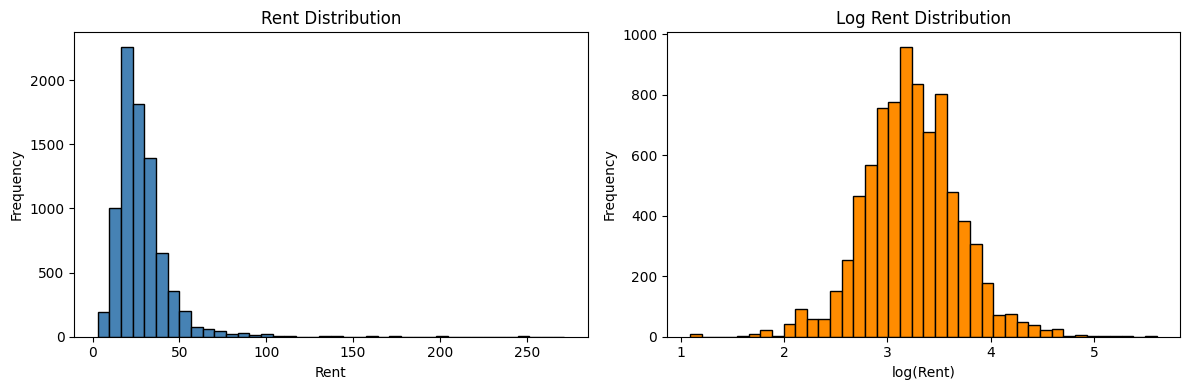

In [9]:
# Compare raw rent and logged rent distributions
fig, axes = subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['Rent'], bins=40, color='steelblue', edgecolor='black')
axes[0].set_title('Rent Distribution')
axes[0].set_xlabel('Rent')
axes[0].set_ylabel('Frequency')

axes[1].hist(df['log_rent'], bins=40, color='darkorange', edgecolor='black')
axes[1].set_title('Log Rent Distribution')
axes[1].set_xlabel('log(Rent)')
axes[1].set_ylabel('Frequency')

fig.tight_layout()

In [38]:
df_dropna = df.dropna(subset=['empl_gr', 'stories', 'age'])

In [178]:
df_dropna['log_rent'].describe()

count    7820.000000
mean        3.241171
std         0.453311
min         1.091923
25%         2.970414
50%         3.226844
75%         3.531641
max         5.521461
Name: log_rent, dtype: float64

In [11]:
df_dropna.isnull().sum()

CS_PropertyID           0
id                      0
idgreen              7141
EPA_ID               7344
size                    0
empl_gr                 0
Rent                    0
leasing_rate            0
stories                 0
age                     0
renovated               0
class_a                 0
class_b                 0
class_c                 0
LEED                    0
Energystar              0
green_rating            0
net                     0
amenities               0
cd_total_07             0
hd_total07              0
total_dd_07             0
Precipitation           0
Gas_Costs               0
Electricity_Costs       0
SEP_Rating           7374
SEP_current          7387
Electricity          7374
Natural_Gas          7374
Other_Energy         7374
Site_EUI             7374
Source_EUI           7374
Emissions            7374
log_rent                0
size_000                0
high_rise               0
mid_rise                0
age_under_10            0
age_10_20   

In [132]:
not_to_include = [
    'CS_PropertyID',
    'idgreen',
    'EPA_ID',
    'LEED', 
    'Energystar'
    'class_c', # Omitted category for class
    'SEP_Rating',
    'SEP_current',
    'Electricity',
    'Natural_Gas',
    'Other_Energy',
    'Site_EUI ',
    'Source_EUI',
    'Emissions ',
    'Rent'
]

# cols = ['Rent', 'log_rent', 'green_rating', 'size', 'age', 'stories', 'renovated',
#         'class_a', 'class_b', 'net', 'amenities', 'leasing_rate',
#         'empl_gr', 'cd_total_07', 'hd_total07', 'Precipitation',
#         'Gas_Costs', 'Electricity_Costs']

green = ['green_rating']

cols_all = ['Rent', 'log_rent', 'size_000', 'age_under_10', 'age_10_20', 
        'age_20_30', 'age_30_40', 'mid_rise', 'high_rise', 'renovated',
        'class_a', 'class_b', 'net', 'amenities', 'leasing_rate', 'empl_gr',
        'cd_total_07', 'hd_total07', 'Precipitation', 'Gas_Costs', 'Electricity_Costs']

cols_ols = ['Rent', 'log_rent', 'size_000', 'age_under_10', 'age_10_20', 
        'age_20_30', 'age_30_40', 'mid_rise', 'high_rise', 'renovated',
        'class_a', 'class_b', 'net', 'amenities', 'leasing_rate']

cols = cols_ols

In [13]:
seed = 42

In [133]:
# Include the Nan rows? Or use df_dropna?

df_model = df_dropna[green + cols + ['id']].copy()

# No train test split for Causal ML? Will be an issue with clusters.
""" gss = skm.GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
train_idx, test_idx = next(gss.split(df_model, groups=df_model['id'])) """;

In [134]:
# De-mean variables other than green_rating

df_model_demeaned = df_model.copy()

cluster_means = df_model.groupby('id')[cols].transform('mean')

df_model_demeaned[cols] = df_model[cols] - cluster_means

In [135]:
X = df_model_demeaned[cols].drop(columns=['Rent', 'log_rent'])
d = df_model_demeaned[green]
y = df_model_demeaned['log_rent']

In [136]:
# Option to get around the clusters for splitting into train and test
# Doing this for assignment, but check if it will ultimately be needed
feat = [c for c in cols if c not in ('Rent', 'log_rent')]

# 1. Row-level split, then make sure every test cluster also has training rows
test = df_model.sample(frac=0.25, random_state=seed)
train = df_model.drop(test.index)
orphan = ~test['id'].isin(train['id'])  
train = pd.concat([train, test[orphan]])    
test = test[~orphan]

# 2. Cluster means from train only
train_means = train.groupby('id')[feat + ['log_rent']].mean()

def demean_and_keep(d):
    m = train_means.reindex(d['id'])
    m.index = d.index
    
    # Create a copy of the dataframe segment
    d_processed = d.copy()
    
    # Overwrite only the ols columns with their de-meaned versions
    d_processed[feat] = d[feat] - m[feat]
    d_processed['log_rent'] = d['log_rent'] - m['log_rent']
    
    return d_processed

train_demeaned = demean_and_keep(train)
test_demeaned = demean_and_keep(test)

In [137]:
X_train = train_demeaned[cols].drop(columns=['Rent', 'log_rent'])
X_test = test_demeaned[cols].drop(columns=['Rent', 'log_rent'])

y_train = train_demeaned['log_rent']
y_test = test_demeaned['log_rent']

In [ ]:
""" model_cols = cols_ols  # Change to cols to use the expanded predictor set.
feature_cols = [col for col in model_cols if col not in ('Rent', 'log_rent')]

df_model = df_dropna[model_cols + ['id']].dropna(
    subset=model_cols + ['id']
).copy()

gss = skm.GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
train_idx, test_idx = next(gss.split(df_model, groups=df_model['id'])) """;

In [ ]:
""" df_train = df_model.iloc[train_idx]
df_test = df_model.iloc[test_idx]

X = df_model[feature_cols]
y = df_model['log_rent']

X_train = df_train[feature_cols]
X_test = df_test[feature_cols]

y_train = df_train['log_rent']
y_test = df_test['log_rent']
groups_train = df_train['id']
groups_test = df_test['id'] """;

In [33]:
# major issue, demeaning treatment means it isn't binary any more
# use mundlauk approach instead?
# Use IRM as main spec, maybe also a PLR for robustness?
# Wait, I don't need to apply de-meaning to the treatment!!!

""" from doubleml import DoubleMLClusterData, DoubleMLIRM
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier


controls = [c for c in cols if c not in ('Rent', 'log_rent', 'green_rating')]  # adjust to your names

cm = df_model.groupby('id')[controls].transform('mean').add_suffix('_cm')
df_model['cluster_size'] = df_model.groupby('id')['id'].transform('count')

x_cols = controls + list(cm.columns) + ['cluster_size']
df_ml = pd.concat([df_model, cm], axis=1)


dml_data = DoubleMLClusterData(
    df_ml, y_col='log_rent', d_cols='green_rating',
    x_cols=x_cols, cluster_cols='id'
)
dml_irm = DoubleMLIRM(dml_data,
                      ml_g=RandomForestRegressor(...),
                      ml_m=RandomForestClassifier(...),
                      trimming_threshold=0.01, n_folds=5)
dml_irm.fit()
dml_irm.summary """;

# OLS

In [ ]:
# For OLS, need to use cols_ols moving forward


df_ols = df_dropna[cols + ['id']].copy()

cluster_means = df_ols.groupby('id')[cols].transform('mean')
df_ols_demeaned = df_ols[cols] - cluster_means

y_ols = df_ols_demeaned['log_rent']
X_ols = df_ols_demeaned.drop(columns=['Rent', 'log_rent'])

In [153]:
df_ols = df[cols + ['id']].copy()

y_ols = df_ols['log_rent']
X_ols = df_ols.drop(columns=['Rent', 'log_rent', 'id'])
id_dummies = pd.get_dummies(df_ols['id'], prefix='id', drop_first=True, dtype=int)
X_ols = pd.concat([X_ols, id_dummies], axis=1)

In [154]:

X_ols_const = sm.add_constant(X_ols)
model = sm.OLS(y_ols, X_ols_const)

In [155]:
results = model.fit(cov_type='cluster', cov_kwds={'groups': df_ols['id']}, use_t=True)

In [156]:
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:               log_rent   R-squared:                       0.720
Model:                            OLS   Adj. R-squared:                  0.693
Method:                 Least Squares   F-statistic:                     841.7
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:18:47   Log-Likelihood:                 9.1535
No. Observations:                8183   AIC:                             1398.
Df Residuals:                    7475   BIC:                             6361.
Df Model:                         707                                         
Covariance Type:              cluster                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            3.3300      0.021    159.096   

/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 707, but rank is 14
  warnings.warn('covariance of constraints does not have full '


In [37]:
print(results.summary().as_latex())

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:}    &    log\_rent     & \textbf{  R-squared:         } &     0.159   \\
\textbf{Model:}            &       OLS        & \textbf{  Adj. R-squared:    } &     0.157   \\
\textbf{Method:}           &  Least Squares   & \textbf{  F-statistic:       } &     82.10   \\
\textbf{Date:}             & Sun, 27 Sep 2026 & \textbf{  Prob (F-statistic):} & 3.71e-136   \\
\textbf{Time:}             &     22:10:51     & \textbf{  Log-Likelihood:    } &    203.76   \\
\textbf{No. Observations:} &        7820      & \textbf{  AIC:               } &    -377.5   \\
\textbf{Df Residuals:}     &        7805      & \textbf{  BIC:               } &    -273.0   \\
\textbf{Df Model:}         &          14      & \textbf{                     } &             \\
\textbf{Covariance Type:}  &     cluster      & \textbf{                     } &             \\
\bottomrule
\end{tabular}
\begin{tabular}{lcccccc}
                        & \textbf{coef}

In [66]:
tbl = results.summary2().tables[1].loc[key_vars].rename(index=labels)
tbl = tbl.rename(index={"Size (sq. ft.)": "Size (thousands of sq. ft.)"})
tbl.columns = ["Coef.", "Std. Err.", "t", "$P>|t|$", "[0.025", "0.975]"]
tbl.index.name = "Variable"

latex = tbl.to_latex(
    float_format="%.4f",
    escape=False,
    label="tab:ols",
    position="H",
    caption=("OLS results with cluster fixed effects, dependent variable: log rent. "
             "Coefficients on building age, stories, renovation, and occupancy are estimated "
             "but omitted from the table. "
             f"N = {int(results.nobs):,}; $R^2$ = {results.rsquared:.3f}."),
)
print(latex)
with open("ols_table.tex", "w") as f:
    f.write(latex)

\begin{table}[H]
\caption{OLS results with cluster fixed effects, dependent variable: log rent. Coefficients on building age, stories, renovation, and occupancy are estimated but omitted from the table. N = 7,820; $R^2$ = 0.730.}
\label{tab:ols}
\begin{tabular}{lrrrrrr}
\toprule
 & Coef. & Std. Err. & t & $P>|t|$ & [0.025 & 0.975] \\
Variable &  &  &  &  &  &  \\
\midrule
Green rating & 0.0245 & 0.0090 & 2.7308 & 0.0065 & 0.0069 & 0.0421 \\
Size (thousands of sq. ft.) & 0.0001 & 0.0000 & 3.1460 & 0.0017 & 0.0000 & 0.0001 \\
Class A & 0.1453 & 0.0158 & 9.1797 & 0.0000 & 0.1143 & 0.1764 \\
Class B & 0.0660 & 0.0123 & 5.3777 & 0.0000 & 0.0419 & 0.0901 \\
Net contract & -0.0414 & 0.0170 & -2.4266 & 0.0155 & -0.0748 & -0.0079 \\
Amenities & 0.0416 & 0.0077 & 5.4008 & 0.0000 & 0.0265 & 0.0567 \\
\bottomrule
\end{tabular}
\end{table}



/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 701, but rank is 14
  warnings.warn('covariance of constraints does not have full '


# Ridge

In [ ]:
""" cluster_means_train = df_train.groupby('id')[model_cols].transform('mean')
df_train_demeaned = df_train[model_cols] - cluster_means_train

cluster_means_test = df_test.groupby('id')[model_cols].transform('mean')
df_test_demeaned = df_test[model_cols] - cluster_means_test
X_train_demeaned = df_train_demeaned - cluster_means_train
X_test_demeaned = df_test_demeaned - cluster_means_test

cluster_means_df_model = df_model.groupby('id')[model_cols].transform('mean')
df_model_demeaned = df_model[model_cols] - cluster_means_df_model

X_demeaned = df_model_demeaned[feature_cols]
y_demeaned = df_model_demeaned['log_rent'] """;

In [ ]:
""" K = 5

gkf = skm.GroupKFold(n_splits=K)
cv_splits = list(gkf.split(X_train, y_train, groups=groups_train))

kfold = skm.KFold(K, random_state=0, shuffle=True) """;

In [111]:
scaler = StandardScaler()
Xs = scaler.fit_transform(df_model_demeaned.drop(columns=['Rent', 'log_rent']))
y_demeaned = df_model_demeaned['log_rent']

In [114]:
alphas = 10**np.linspace(8, -2, 100) / y_demeaned.std()

soln_array = skl.ElasticNet.path(Xs,
                                 y_demeaned,
                                 l1_ratio=0.,
                                 alphas=alphas)[1]
soln_array.shape

(13, 100)

In [113]:


soln_path = pd.DataFrame(soln_array.T,
                         columns=df_model.drop(columns=['Rent', 'log_rent', 'id']).columns,
                         index=-np.log(alphas))
soln_path.index.name = 'negative log(lambda)'
soln_path

,size_000,age_under_10,age_10_20,age_20_30,age_30_40,mid_rise,high_rise,renovated,class_a,class_b,net,amenities,leasing_rate
negative log(lambda),,,,,,,,,,,,,
-19.213214,1.744657e-10,1.305003e-10,1.865962e-10,3.294077e-11,5.722881e-11,1.791446e-10,8.789565e-11,-2.785924e-10,5.029293e-10,-2.634717e-10,-8.038796e-11,1.619710e-10,4.059141e-10
-18.980629,2.201507e-10,1.646728e-10,2.354577e-10,4.156653e-11,7.221457e-11,2.260549e-10,1.109117e-10,-3.515437e-10,6.346248e-10,-3.324635e-10,-1.014381e-10,2.043842e-10,5.122055e-10
-18.748045,2.777987e-10,2.077934e-10,2.971139e-10,5.245101e-11,9.112445e-11,2.852489e-10,1.399547e-10,-4.435979e-10,8.008057e-10,-4.195214e-10,-1.280004e-10,2.579036e-10,6.463300e-10
-18.515461,3.505422e-10,2.622056e-10,3.749152e-10,6.618567e-11,1.149860e-10,3.599433e-10,1.766028e-10,-5.597570e-10,1.010502e-09,-5.293759e-10,-1.615181e-10,3.254374e-10,8.155760e-10
-18.282876,4.423341e-10,3.308659e-10,4.730893e-10,8.351684e-11,1.450959e-10,4.541969e-10,2.228475e-10,-7.063332e-10,1.275109e-09,-6.679967e-10,-2.038128e-10,4.106554e-10,1.029140e-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2.882300,-7.553868e-05,-5.321744e-03,-1.006132e-03,-2.594301e-02,-1.264868e-03,4.074539e-02,-5.157709e-03,-5.531630e-02,1.228895e-01,2.912692e-02,-2.795383e-02,-1.320243e-02,6.725209e-02
3.114884,-4.862641e-04,-6.681200e-03,-2.440454e-03,-2.783603e-02,-2.123586e-03,4.067475e-02,-5.796052e-03,-5.649885e-02,1.280015e-01,3.229629e-02,-2.832288e-02,-1.396609e-02,6.771272e-02
3.347469,-8.363563e-04,-7.895814e-03,-3.725909e-03,-2.951901e-02,-2.901901e-03,4.055102e-02,-6.393148e-03,-5.751136e-02,1.324968e-01,3.510217e-02,-2.862214e-02,-1.461075e-02,6.806404e-02


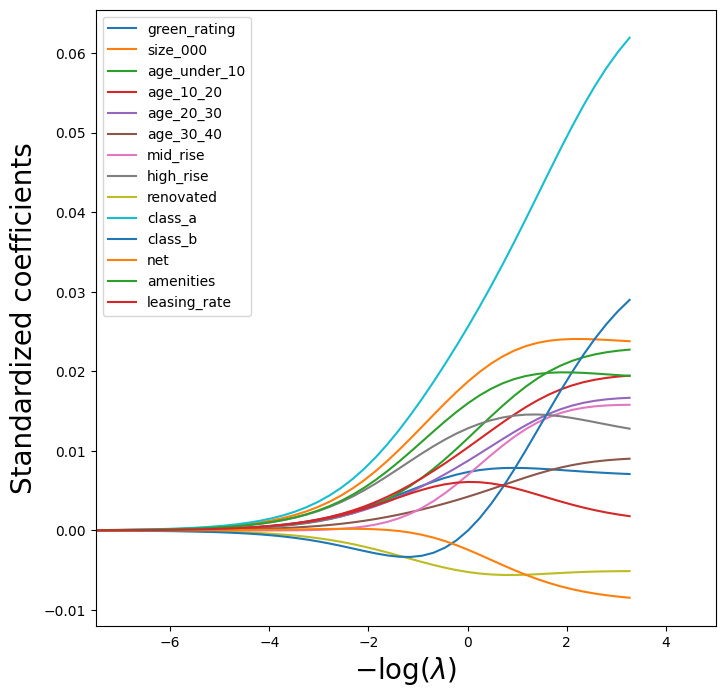

In [265]:
path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_xlim([-7.5, 5])
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(loc='upper left');


In [115]:
ridge = skl.ElasticNet(l1_ratio=0)
scaler = StandardScaler(with_mean=True,  with_std=True)
pipe = Pipeline(steps=[('scaler', scaler), ('ridge', ridge)])
pipe.fit(X_demeaned, y_demeaned)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None


In [116]:
ridge_results = skm.cross_validate(
    pipe, X_demeaned, y_demeaned, cv=kfold, scoring='neg_mean_squared_error'
)
-ridge_results['test_score'].mean()

np.float64(0.18506641996452608)

In [117]:
param_grid = {'ridge__alpha': alphas}

grid = skm.GridSearchCV(
    pipe,
    param_grid,
    cv=kfold,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid.fit(X_demeaned, y_demeaned)
grid.best_params_['ridge__alpha']
grid.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",np.float64(120.66085728646907)
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None


In [263]:
-grid.best_score_

np.float64(0.05879428249153068)

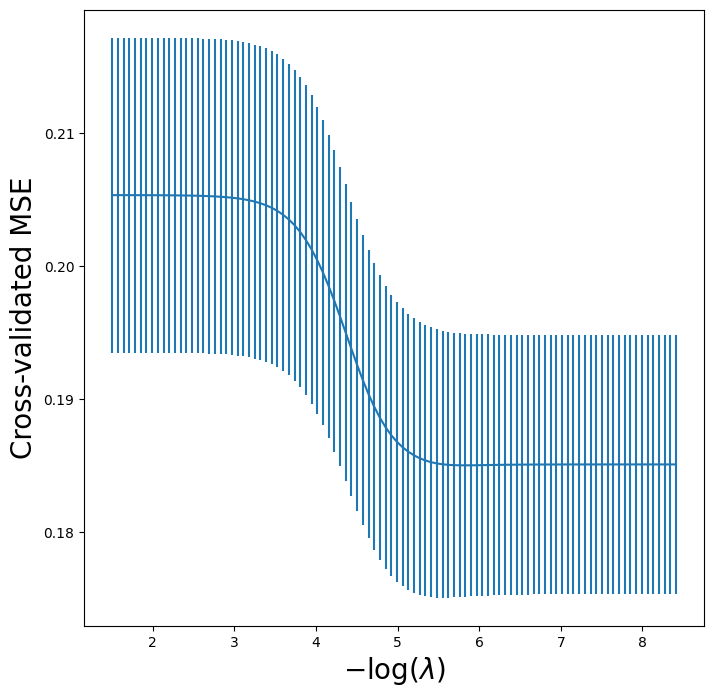

In [125]:
ridge_fig, ax = subplots(figsize=(8,8))
ax.errorbar(-np.log(alphas),
            -grid.cv_results_['mean_test_score'],
            yerr=grid.cv_results_['std_test_score'] / np.sqrt(K))
# ax.set_ylim([0.15,0.25])
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20);

# Lasso

In [121]:
lassoCV = skl.ElasticNetCV(
    n_alphas=100,
    l1_ratio=1,
    cv=kfold
)

pipe_cv = Pipeline(
    steps=[('scaler', scaler), ('lasso', lassoCV)]
)
pipe_cv.fit(X_demeaned, y_demeaned)
tuned_lasso = pipe_cv.named_steps['lasso']
tuned_lasso.alpha_

np.float64(0.004809093999558639)

In [122]:
scaler_fitted = pipe_cv.named_steps['scaler']
X_demeaned_scaled = scaler_fitted.transform(X_demeaned)

In [123]:
alphas, soln_array = skl.Lasso.path(X_demeaned_scaled,
                                    y_demeaned,
                                    l1_ratio=1,
                                    n_alphas=100)[:2]
soln_path = pd.DataFrame(soln_array.T,
                         columns=X_demeaned.columns,
                         index=-np.log(alphas))

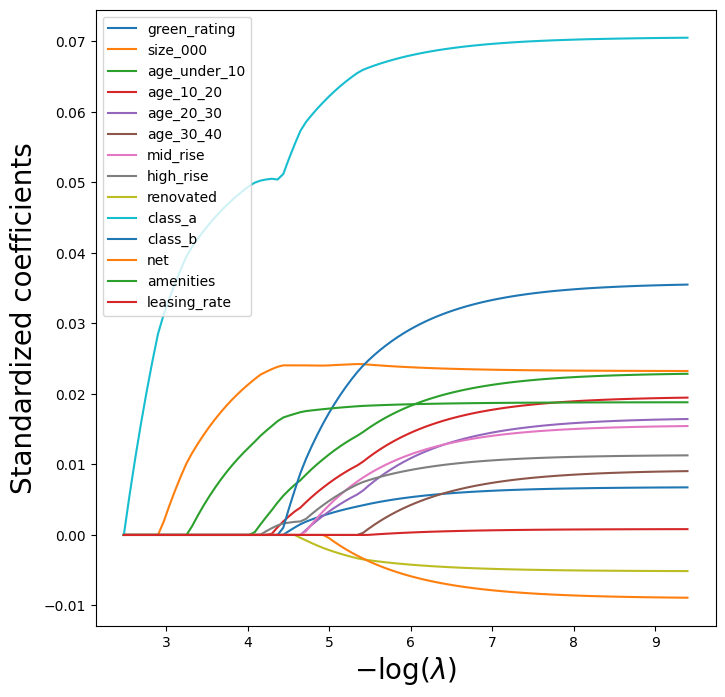

In [251]:
path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.legend(loc='upper left')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20);


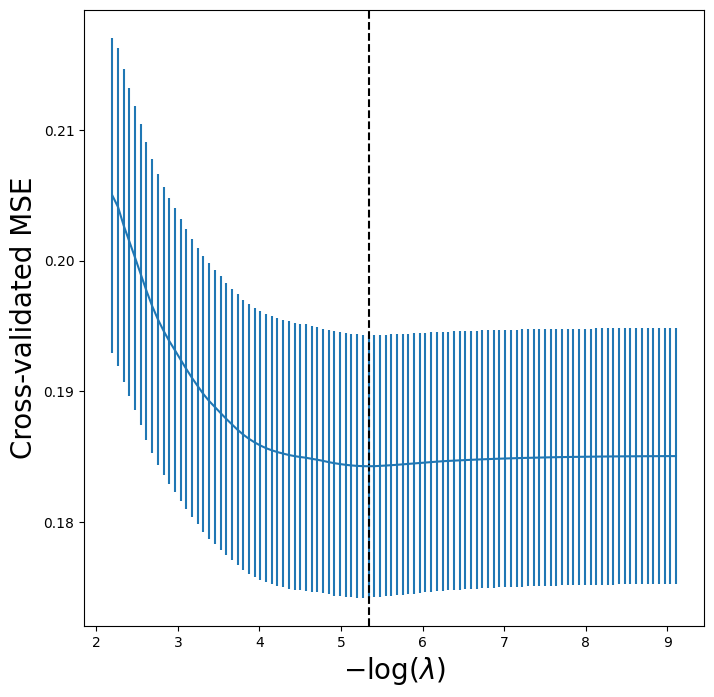

In [124]:
lassoCV_fig, ax = subplots(figsize=(8,8))
ax.errorbar(-np.log(tuned_lasso.alphas_),
            tuned_lasso.mse_path_.mean(1),
            yerr=tuned_lasso.mse_path_.std(1) / np.sqrt(K))
ax.axvline(-np.log(tuned_lasso.alpha_), c='k', ls='--')
# ax.set_ylim([50000,250000])
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20);

# Report 4

## Decision Tree

In [138]:
tree = DTR(random_state=seed)

In [140]:
param_grid = {
    'ccp_alpha': [0.0, *np.logspace(-10, -4, 12)],
    'max_depth': [3],
    'min_samples_leaf': [5, 10, 25, 50],
    'min_samples_split': [2, 10, 25]
}

tree_cv = skm.GroupKFold(n_splits=5)
grid_tree = skm.GridSearchCV(
    DTR(random_state=seed),
    param_grid=param_grid,
    cv=tree_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)
G = grid_tree.fit(X_train, y_train, groups=train['id'])
best_tree = grid_tree.best_estimator_

print(f'Best grouped CV MSE: {-grid_tree.best_score_:,.4f}')
print(f'Best parameters: {grid_tree.best_params_}')

Fitting 5 folds for each of 156 candidates, totalling 780 fits
Best grouped CV MSE: 0.0559
Best parameters: {'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}


In [141]:
tree_mse = mean_squared_error(y_test, best_tree.predict(X_test))
tree_rmse = np.sqrt(tree_mse)

print(f'Test MSE: {tree_mse:.4f}')
print(f'Test RMSE: {tree_rmse:.4f}')

Test MSE: 0.0678
Test RMSE: 0.2604


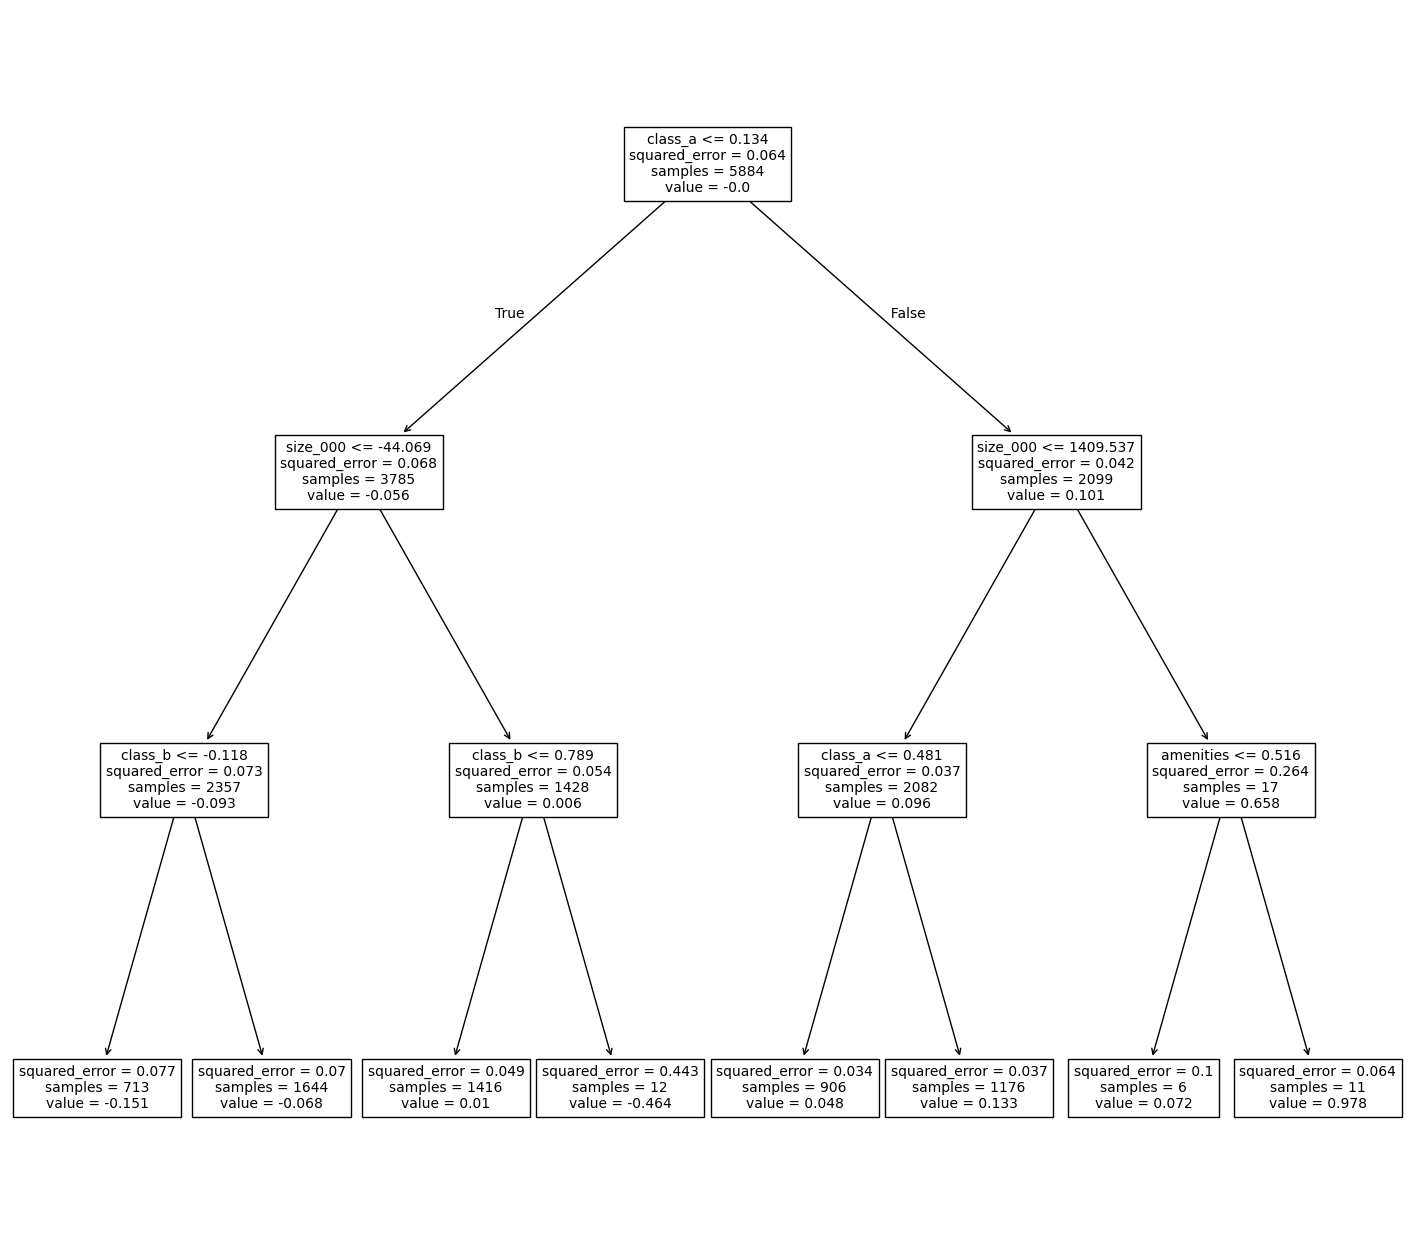

In [172]:
ax = subplots(figsize=(18, 16))[1]
plot_tree(best_tree, feature_names=X_train.columns, ax=ax, fontsize=10);

In [145]:
tree_feature_imp = pd.DataFrame(
    {'importance':best_tree.feature_importances_},
    index=X_train.columns)
tree_feature_imp.sort_values(by='importance', ascending=False)

,importance
class_a,0.610592
size_000,0.234723
class_b,0.101667
amenities,0.053018
age_under_10,0.000000
age_10_20,0.000000
age_20_30,0.000000
age_30_40,0.000000
mid_rise,0.000000
high_rise,0.000000


## Random Forest

In [148]:
rf = RF(max_features=5, random_state=seed)
rf_cv = skm.GroupKFold(n_splits=5)
rf_cv_scores = skm.cross_val_score(
    rf,
    X_train,
    y_train,
    groups=train['id'],
    cv=rf_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
rf_cv_mse = -rf_cv_scores
rf_cv_mse_mean = rf_cv_mse.mean()
rf_cv_mse_se = rf_cv_mse.std(ddof=1) / np.sqrt(len(rf_cv_mse))

rf.fit(X_train, y_train)
rf_test_predictions = rf.predict(X_test)
rf_test_mse = mean_squared_error(y_test, rf_test_predictions)
rf_test_rmse = np.sqrt(rf_test_mse)

print(f'Grouped CV MSE: {rf_cv_mse_mean:.4f} (SE: {rf_cv_mse_se:.4f})')
print(f'Test MSE: {rf_test_mse:.4f}')
print(f'Test RMSE: {rf_test_rmse:.4f}')

Grouped CV MSE: 0.0448 (SE: 0.0037)
Test MSE: 0.0530
Test RMSE: 0.2302


In [147]:
feature_imp = pd.DataFrame(
    {'importance':rf.feature_importances_},
    index=X_train.columns)
feature_imp.sort_values(by='importance', ascending=False)

,importance
size_000,0.184259
leasing_rate,0.121351
class_a,0.106948
class_b,0.083523
amenities,0.079371
renovated,0.076329
age_20_30,0.070916
high_rise,0.067602
mid_rise,0.063914
age_30_40,0.050385


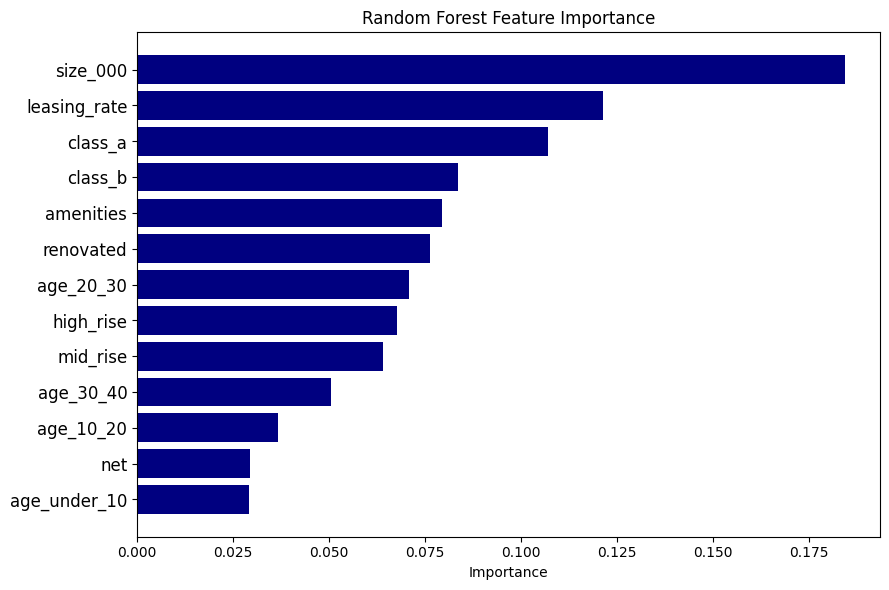

In [175]:
rf_importance = pd.Series(
    rf.feature_importances_, index=X_train.columns, name='importance'
).sort_values()

fig, ax = subplots(figsize=(9, 6))
ax.barh(rf_importance.index, rf_importance.values, color='navy')
ax.set_title('Random Forest Feature Importance')
ax.set_xlabel('Importance')
ax.tick_params(axis='y', labelsize=12)
fig.tight_layout()

## Bagging Model

In [151]:
bagging_model = BAG(
    estimator=DTR(max_features=None, random_state=seed),
    n_estimators=100,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    random_state=seed,
    n_jobs=1
)

bagging_cv = skm.GroupKFold(n_splits=5)
bagging_cv_scores = skm.cross_val_score(
    bagging_model,
    X_train,
    y_train,
    groups=train['id'],
    cv=bagging_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
bagging_cv_mse = -bagging_cv_scores
bagging_cv_mse_mean = bagging_cv_mse.mean()
bagging_cv_mse_se = bagging_cv_mse.std(ddof=1) / np.sqrt(len(bagging_cv_mse))

bagging_model.fit(X_train, y_train)
bagging_test_predictions = bagging_model.predict(X_test)
bagging_test_mse = mean_squared_error(y_test, bagging_test_predictions)
bagging_test_rmse = np.sqrt(bagging_test_mse)

print(f'Grouped CV MSE: {bagging_cv_mse_mean:.4f} (SE: {bagging_cv_mse_se:.4f})')
print(f'Test MSE: {bagging_test_mse:.4f}')
print(f'Test RMSE: {bagging_test_rmse:.4f}')

Grouped CV MSE: 0.0463 (SE: 0.0034)
Test MSE: 0.0550
Test RMSE: 0.2344


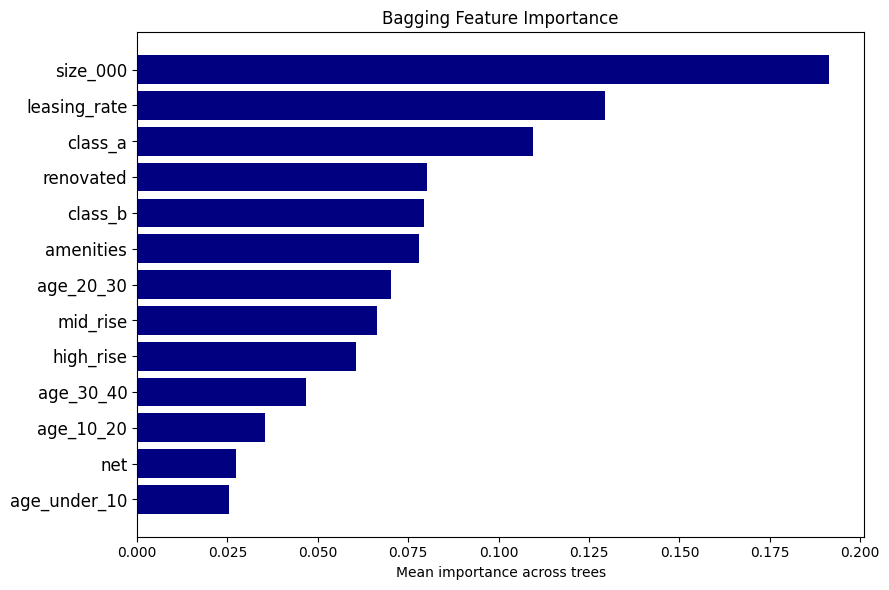

In [176]:
bagging_importance_values = np.zeros(X_train.shape[1])
for estimator, feature_indices in zip(
    bagging_model.estimators_, bagging_model.estimators_features_
):
    bagging_importance_values[feature_indices] += estimator.feature_importances_
bagging_importance_values /= len(bagging_model.estimators_)

bagging_importance = pd.Series(
    bagging_importance_values,
    index=X_train.columns,
    name='importance'
).sort_values()

fig, ax = subplots(figsize=(9, 6))
ax.barh(bagging_importance.index, bagging_importance.values, color='navy')
ax.set_title('Bagging Feature Importance')
ax.set_xlabel('Mean importance across trees')
ax.tick_params(axis='y', labelsize=12)
fig.tight_layout()

## Boosting Model

In [157]:
boosting_model = GBR(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=seed
)

boosting_cv = skm.GroupKFold(n_splits=5)
boosting_cv_scores = skm.cross_val_score(
    boosting_model,
    X_train,
    y_train,
    groups=train['id'],
    cv=boosting_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
boosting_cv_mse = -boosting_cv_scores
boosting_cv_mse_mean = boosting_cv_mse.mean()
boosting_cv_mse_se = boosting_cv_mse.std(ddof=1) / np.sqrt(len(boosting_cv_mse))

boosting_model.fit(X_train, y_train)
boosting_test_predictions = boosting_model.predict(X_test)
boosting_test_mse = mean_squared_error(y_test, boosting_test_predictions)
boosting_test_rmse = np.sqrt(boosting_test_mse)

print(f'Grouped CV MSE: {boosting_cv_mse_mean:.4f} (SE: {boosting_cv_mse_se:.4f})')
print(f'Test MSE: {boosting_test_mse:.4f}')
print(f'Test RMSE: {boosting_test_rmse:.4f}')

Grouped CV MSE: 0.0519 (SE: 0.0030)
Test MSE: 0.0631
Test RMSE: 0.2512


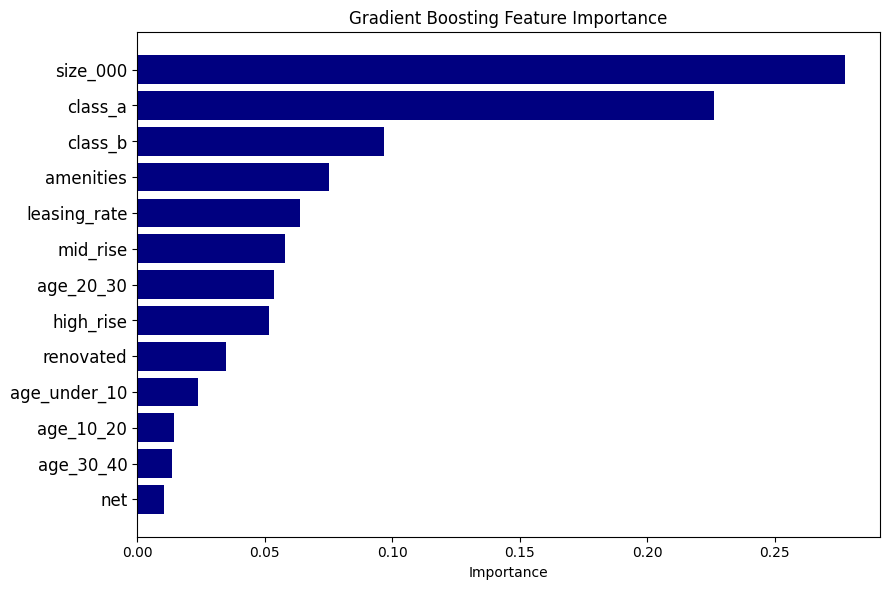

In [177]:
boosting_importance = pd.Series(
    boosting_model.feature_importances_,
    index=X_train.columns,
    name='importance'
).sort_values()

fig, ax = subplots(figsize=(9, 6))
ax.barh(boosting_importance.index, boosting_importance.values, color='navy')
ax.set_title('Gradient Boosting Feature Importance')
ax.set_xlabel('Importance')
ax.tick_params(axis='y', labelsize=12)
fig.tight_layout()

## Prediction Error Summary

In [162]:
model_error_summary = pd.DataFrame([
    {
        'Model': 'Tree',
        'Test MSE': tree_mse,
        'Test RMSE': tree_rmse
    },
    {
        'Model': 'Bagging',
        'Test MSE': bagging_test_mse,
        'Test RMSE': bagging_test_rmse
    },
    {
        'Model': 'Random Forest',
        'Test MSE': rf_test_mse,
        'Test RMSE': rf_test_rmse
    },
    {
        'Model': 'Boosting',
        'Test MSE': boosting_test_mse,
        'Test RMSE': boosting_test_rmse
    }
]).set_index('Model')

model_error_summary.round(4)

,Test MSE,Test RMSE
Model,,
Tree,0.0678,0.2604
Bagging,0.0550,0.2344
Random Forest,0.0530,0.2302
Boosting,0.0631,0.2512


In [164]:
summary_table_latex = model_error_summary.to_latex(index=True)
print(summary_table_latex)

\begin{tabular}{lrr}
\toprule
 & Test MSE & Test RMSE \\
Model &  &  \\
\midrule
Tree & 0.067803 & 0.260391 \\
Bagging & 0.054962 & 0.234440 \\
Random Forest & 0.053004 & 0.230227 \\
Boosting & 0.063121 & 0.251240 \\
\bottomrule
\end{tabular}

